# TP2 — Teste de Performance: Trie e Grafos
## Estruturas de Dados e Algoritmos Avançados

**Aluno:** João Victor Martins

**Organização do notebook**
- Cada exercício traz o enunciado, o código, a execução e a análise.
- O código é orientado a objetos: `TrieNode` e `Trie` (Exercícios 1 a 6) e `GraphAdjList` e `GraphAdjMatrix` (Exercícios 7 a 10). O estado fica em atributos (`children`, `is_end`, `root`, `adj`, `index`, `mat`) e o comportamento em métodos.
- A classe `Trie` é criada no Exercício 1 com `insert`. Os métodos pedidos nos exercícios seguintes (`search`, `starts_with`, `_collect_words`, `autocomplete`, `autocorrect`) são acrescentados à mesma classe com o decorador `@add_method(Trie)`, para que cada um fique logo abaixo do seu enunciado. O mesmo vale para `to_mermaid` em `GraphAdjList`. A interface final de cada classe é listada no Exercício 12.
- Os testes usam `assert`: se qualquer resultado for diferente do esperado, a célula falha. As tabelas mostram o valor esperado e o obtido.

---
### Exercício 1: Implementação de Trie com inserção e marcação de fim de palavra

**Introdução**
Tries são estruturas centrais em sistemas que realizam busca por prefixo, indexação lexicográfica e validação rápida de cadeias. Em aplicações profissionais, elas aparecem em mecanismos de autocomplete, correção ortográfica, roteamento por prefixo e sistemas de classificação textual. O valor prático da trie não está apenas em armazenar palavras, mas em preservar uma estrutura em que o caminho na árvore representa a própria informação.

**Tarefa**
1. Implemente uma classe `TrieNode` (um "nó" da Trie) contendo os seguintes **atributos**:
   - a. Um dicionário `children` para mapear caracteres para nós filhos.
   - b. Um booleano `is_end` para marcar fim de palavra.
2. Implemente uma classe `Trie` (a estrutura como um todo) contendo:
   - a. Um atributo `root` do tipo `TrieNode`.
   - b. Um método `insert(word)` para inserir palavras.
3. Garanta que sua Trie suporte palavras que são prefixo de outras (por exemplo: car, cart, carro).
4. No notebook, crie um conjunto de testes mínimos (entradas e saídas esperadas) que validem:
   - a. Inserção de palavra nova.
   - b. Inserção repetida da mesma palavra.
   - c. Inserção de palavra que é prefixo de outra.

In [1]:
def add_method(cls):
    """Decorador usado nos exercícios seguintes: registra a função decorada como
    método da classe `cls`. Assim cada método fica logo abaixo do enunciado que o pede,
    e mesmo assim pertence à classe (recebe `self` e atua sobre o estado do objeto)."""
    def decorator(func):
        setattr(cls, func.__name__, func)
        return func
    return decorator


class TrieNode:
    """Um nó da Trie.

    Atributos (estado):
        children: dict[str, TrieNode]  -> mapeia UM caractere para o nó filho.
        is_end:   bool                 -> True se o caminho raiz -> este nó forma uma palavra inserida.

    O nó não guarda a palavra nem o próprio caractere: a palavra é o CAMINHO
    de chaves de `children` percorrido desde a raiz.
    """
    __slots__ = ('children', 'is_end')

    def __init__(self):
        self.children = {}
        self.is_end = False


class Trie:
    """Árvore de prefixos.

    Atributos (estado):
        root:  TrieNode  -> nó raiz, que representa o prefixo vazio "".
        size:  int       -> quantidade de palavras DISTINTAS armazenadas.
        nodes: int       -> quantidade de nós (inclui a raiz); usado nas análises de custo.

    Invariante: um nó tem is_end=True se e somente se a palavra formada pelo seu
    caminho foi inserida. Todo nó que não é a raiz está no caminho de pelo menos uma palavra.

    Decisões de entrada (válidas para todos os métodos):
      - a Trie diferencia maiúsculas de minúsculas ("Car" e "car" são palavras diferentes);
      - a palavra vazia "" NÃO é uma palavra válida: insert("") levanta ValueError (ver Exercício 2).
    """

    def __init__(self):
        self.root = TrieNode()
        self.size = 0
        self.nodes = 1

    @staticmethod
    def _validate(word):
        if not isinstance(word, str):
            raise TypeError(f"a palavra deve ser str, recebido {type(word).__name__}")

    def insert(self, word):
        """Insere `word`. Devolve True se a palavra é nova e False se já existia.
        Percorre um caractere por vez, criando os nós que faltam: O(L), L = len(word)."""
        self._validate(word)
        if word == "":
            raise ValueError("a palavra vazia não é aceita na Trie")
        node = self.root
        for ch in word:
            nxt = node.children.get(ch)
            if nxt is None:                      # caminho ainda não existe: cria o nó
                nxt = TrieNode()
                node.children[ch] = nxt
                self.nodes += 1
            node = nxt
        if node.is_end:                          # inserção repetida: nada muda
            return False
        node.is_end = True                       # marca o FIM da palavra
        self.size += 1
        return True

    def __len__(self):
        return self.size

    def __repr__(self):
        return f"Trie({self.size} palavras, {self.nodes} nós)"


def show_trie(trie):
    """Desenha a Trie (filhos em ordem alfabética); '*' marca nós com is_end=True."""
    def rec(node, prefix, indent):
        for ch in sorted(node.children):
            child = node.children[ch]
            print(f"{indent}{ch}{' *' if child.is_end else ''}   ({prefix + ch})")
            rec(child, prefix + ch, indent + "  ")
    print("(raiz)")
    rec(trie.root, "", "  ")


# ---------------- Testes mínimos (Tarefa 4) ----------------
t = Trie()

# a) inserção de palavra nova
assert t.insert("carro") is True
assert t.size == 1 and t.nodes == 6                      # raiz + c, a, r, r, o
print("a) insert('carro') -> True | palavras:", t.size, "| nós:", t.nodes)

# b) inserção repetida da mesma palavra: não duplica nem cria nós
assert t.insert("carro") is False
assert t.size == 1 and t.nodes == 6
print("b) insert('carro') de novo -> False | palavras:", t.size, "| nós:", t.nodes, "(nada mudou)")

# c) palavra que é prefixo de outra (e o contrário): compartilham o caminho
assert t.insert("car") is True                           # 'car' é prefixo de 'carro': só marca is_end
assert t.nodes == 6
assert t.insert("cart") is True                          # 'cart' estende 'car': cria só o nó 't'
assert t.nodes == 7
print("c) insert('car') -> True, sem criar nós (só marca is_end no 'r');"
      " insert('cart') -> True, criando 1 nó | nós:", t.nodes)

# estado interno conferido diretamente nos atributos
n = t.root.children['c'].children['a'].children['r']
assert n.is_end is True and set(n.children) == {'r', 't'}
assert n.children['r'].is_end is False                   # 'carr' não é palavra
assert n.children['r'].children['o'].is_end is True      # 'carro' é
print("\nEstado interno: nó 'car' -> is_end =", n.is_end, "| filhos =", sorted(n.children),
      "| nó 'carr' -> is_end =", n.children['r'].is_end)
print(t)
show_trie(t)

# entradas inválidas
for bad in ["", None, 42]:
    try:
        t.insert(bad); raise AssertionError
    except (ValueError, TypeError) as e:
        print(f"insert({bad!r}) -> {type(e).__name__}: {e}")

a) insert('carro') -> True | palavras: 1 | nós: 6
b) insert('carro') de novo -> False | palavras: 1 | nós: 6 (nada mudou)
c) insert('car') -> True, sem criar nós (só marca is_end no 'r'); insert('cart') -> True, criando 1 nó | nós: 7

Estado interno: nó 'car' -> is_end = True | filhos = ['r', 't'] | nó 'carr' -> is_end = False
Trie(3 palavras, 7 nós)
(raiz)
  c   (c)
    a   (ca)
      r *   (car)
        r   (carr)
          o *   (carro)
        t *   (cart)
insert('') -> ValueError: a palavra vazia não é aceita na Trie
insert(None) -> TypeError: a palavra deve ser str, recebido NoneType
insert(42) -> TypeError: a palavra deve ser str, recebido int


*Análise*
- **Estrutura:** a palavra não é guardada em nenhum nó; ela é o **caminho** de chaves de `children` desde a raiz. Por isso `car`, `carro` e `cart` compartilham os nós `c → a → r`, e a Trie com as três palavras tem só 7 nós (raiz + 6).
- **Prefixos (Tarefa 3):** o que distingue `car` de `carr` é apenas o `is_end`. Inserir `car` depois de `carro` não cria nenhum nó, só marca `is_end=True` no `r`. Inserir `cart` cria um único nó (`t`).
- **Testes (Tarefa 4):** os três casos são conferidos por `assert` no valor devolvido, na contagem de palavras e na contagem de nós:

| Caso | Entrada | Saída esperada | Palavras / nós depois |
|---|---|---|---|
| a) palavra nova | `insert('carro')` | `True` | 1 / 6 |
| b) repetida | `insert('carro')` | `False`, nada muda | 1 / 6 |
| c) prefixo de outra | `insert('car')` | `True`, sem criar nós | 2 / 6 |
| c) extensão de outra | `insert('cart')` | `True`, cria 1 nó | 3 / 7 |

- **Decisões:** `insert` devolve `True`/`False` para que quem chama saiba se a palavra era nova (e `size` não conta repetidas). A palavra vazia é recusada com `ValueError` e tipos diferentes de `str` com `TypeError`. A Trie diferencia maiúsculas de minúsculas.
- **Custo:** `insert` percorre um nó por caractere: $O(L)$, com $L$ = tamanho da palavra, independentemente de quantas palavras já existam.

---
### Exercício 2: Busca exata em Trie (search)

**Introdução**
Busca exata em trie é uma operação conceitualmente simples, mas frequentemente implementada de forma incorreta quando se confunde "prefixo existente" com "palavra existente". Em produção, esse erro gera efeitos graves: sistemas sugerem ou aceitam tokens inválidos, validações falham e logs ficam inconsistentes. Em termos de OO, isso significa que seu método `search(word)` precisa diferenciar dois estados: (1) o caminho existe em `children` e (2) o nó final possui o atributo `is_end=True`. Essa distinção é uma das invariantes funcionais mais importantes da Trie.

**Tarefa**
1. Implemente o método `search(word)` na classe `Trie`, retornando `True` apenas se `word` for uma palavra completa na trie.
2. Faça testes cobrindo obrigatoriamente:
   - a. Palavra existente.
   - b. Palavra inexistente com prefixo existente.
   - c. Prefixo existente que não é palavra (por exemplo: car existe, mas ca não).
   - d. Palavra vazia, se você decidir suportá-la (documente sua decisão).
3. Documente no notebook a regra que diferencia prefixo de palavra completa na sua implementação.

In [2]:
@add_method(Trie)
def _find_node(self, prefix):
    """Desce pelo caminho de `prefix` e devolve o nó final, ou None se o caminho
    não existe. É a base comum de search, starts_with e autocomplete. O(len(prefix))."""
    node = self.root
    self.last_steps = 0                       # nós percorridos (usado nas medições do Ex. 12)
    for ch in prefix:
        self.last_steps += 1
        node = node.children.get(ch)
        if node is None:
            return None
    return node


@add_method(Trie)
def search(self, word):
    """True somente se `word` é uma PALAVRA COMPLETA inserida.
    Regra: (1) o caminho de `word` precisa existir em children
           E (2) o nó final precisa ter is_end=True.
    Só a condição (1) significa apenas 'é prefixo de alguma palavra'."""
    self._validate(word)
    if word == "":
        return False                 # decisão: a palavra vazia nunca é palavra (insert também a recusa)
    node = self._find_node(word)
    return node is not None and node.is_end


t = Trie()
for w in ["car", "cart", "carro", "casa", "dado"]:
    t.insert(w)
print("Palavras inseridas:", ["car", "cart", "carro", "casa", "dado"], "\n")

casos = [
    ("a) palavra existente",                       "carro", True),
    ("a) palavra existente que é prefixo de outra", "car",   True),
    ("b) inexistente com prefixo existente",       "carta", False),
    ("b) inexistente com prefixo existente",       "casas", False),
    ("c) prefixo existente que não é palavra",     "ca",    False),
    ("c) prefixo existente que não é palavra",     "carr",  False),
    ("inexistente sem prefixo em comum",           "bola",  False),
    ("d) palavra vazia",                           "",      False),
]
print(f"{'caso':<44}{'busca':<10}{'caminho existe?':<17}{'is_end do nó':<14}{'search'}")
for nome, w, esperado in casos:
    node = t._find_node(w)
    caminho = node is not None
    fim = node.is_end if node else '—'
    r = t.search(w)
    assert r == esperado, (w, r)
    print(f"{nome:<44}{w!r:<10}{str(caminho):<17}{str(fim):<14}{r}")

Palavras inseridas: ['car', 'cart', 'carro', 'casa', 'dado'] 

caso                                        busca     caminho existe?  is_end do nó  search
a) palavra existente                        'carro'   True             True          True
a) palavra existente que é prefixo de outra 'car'     True             True          True
b) inexistente com prefixo existente        'carta'   False            —             False
b) inexistente com prefixo existente        'casas'   False            —             False
c) prefixo existente que não é palavra      'ca'      True             False         False
c) prefixo existente que não é palavra      'carr'    True             False         False
inexistente sem prefixo em comum            'bola'    False            —             False
d) palavra vazia                            ''        True             False         False


*Regra que diferencia prefixo de palavra completa (Tarefa 3)*

| Situação | (1) caminho existe em `children`? | (2) `is_end` do nó final | É prefixo? | É palavra? |
|---|---|---|---|---|
| `carro` | sim | `True` | sim | **sim** |
| `ca`, `carr` | sim | `False` | sim | **não** |
| `carta`, `bola` | não | — | não | **não** |

- **`search(word)` devolve `True` se e somente se (1) E (2) valem.** A condição (1) sozinha significa apenas que alguma palavra começa com `word`; é o que o `starts_with` do Exercício 3 verifica. Os dois métodos usam o mesmo `_find_node` e diferem só nessa segunda condição, o que deixa a regra em um único lugar do código.
- **Testes (Tarefa 2):** a tabela da saída mostra, para cada caso, as duas condições e o resultado: `carro` e `car` são palavras; `carta` e `casas` têm prefixo existente mas o caminho termina antes; `ca` e `carr` têm caminho completo mas `is_end=False`.
- **Palavra vazia (2.d):** decidi **não** suportá-la. O caminho de `""` é a própria raiz, que existe sempre; se a raiz pudesse ter `is_end=True`, a "palavra vazia" passaria a aparecer no autocomplete de qualquer prefixo vazio e no autocorrect, sem significado para o usuário. Por coerência, `insert("")` levanta `ValueError` e `search("")` devolve `False`.
- **Custo:** $O(L)$, com no máximo $L$ acessos a `children` (dicionário, $O(1)$ em média).

---
### Exercício 3: Busca por prefixo (starts_with) como base de autocomplete

**Introdução**
Sistemas de autocomplete raramente dependem de busca exata: eles dependem de localizar rapidamente o nó correspondente a um prefixo e, a partir dele, enumerar sugestões. Um erro comum é misturar lógica de "encontrar o nó do prefixo" com lógica de "gerar lista de palavras", gerando repetição de trabalho e código difícil de manter. Em OO, isso costuma ser resolvido separando responsabilidades: um método para localizar o nó (`starts_with` ou uma busca interna por prefixo) e outro para coletar palavras a partir dele.

**Tarefa**
1. Implemente o método `starts_with(prefix)` que retorna `True` se existe algum caminho na trie para esse prefixo.
2. Faça testes com:
   - a. Prefixo que existe.
   - b. Prefixo que não existe.
   - c. Prefixo que é uma palavra completa.
3. Registre no notebook pelo menos 5 exemplos de prefixos testados e seus resultados.

In [3]:
@add_method(Trie)
def starts_with(self, prefix):
    """True se existe algum caminho na Trie para `prefix`, ou seja, se ao menos uma
    palavra inserida começa com `prefix`. Diferente de search, NÃO exige is_end.
    O prefixo vazio é o caminho da raiz: True se a Trie tem alguma palavra. O(len(prefix))."""
    self._validate(prefix)
    if prefix == "":
        return self.size > 0
    return self._find_node(prefix) is not None


t = Trie()
palavras = ["car", "cart", "carro", "casa", "dado", "dados", "data"]
for w in palavras:
    t.insert(w)
print("Palavras inseridas:", palavras, "\n")

exemplos = [
    ("a) prefixo que existe",             "ca",    True),
    ("a) prefixo que existe",             "dad",   True),
    ("a) prefixo que existe",             "carr",  True),
    ("b) prefixo que não existe",         "cx",    False),
    ("b) prefixo que não existe",         "bola",  False),
    ("b) prefixo maior que as palavras",  "carros", False),
    ("c) prefixo que é palavra completa", "car",   True),
    ("c) prefixo que é palavra completa", "dado",  True),
    ("prefixo vazio",                     "",      True),
]
print(f"{'caso':<36}{'prefixo':<10}{'starts_with':<13}{'search':<8}palavras com esse prefixo (conferência)")
for nome, p, esperado in exemplos:
    r = t.starts_with(p)
    conferencia = [w for w in palavras if w.startswith(p)]
    assert r == esperado == bool(conferencia), p
    print(f"{nome:<36}{p!r:<10}{str(r):<13}{str(t.search(p)):<8}{conferencia}")

Palavras inseridas: ['car', 'cart', 'carro', 'casa', 'dado', 'dados', 'data'] 

caso                                prefixo   starts_with  search  palavras com esse prefixo (conferência)
a) prefixo que existe               'ca'      True         False   ['car', 'cart', 'carro', 'casa']
a) prefixo que existe               'dad'     True         False   ['dado', 'dados']
a) prefixo que existe               'carr'    True         False   ['carro']
b) prefixo que não existe           'cx'      False        False   []
b) prefixo que não existe           'bola'    False        False   []
b) prefixo maior que as palavras    'carros'  False        False   []
c) prefixo que é palavra completa   'car'     True         True    ['car', 'cart', 'carro']
c) prefixo que é palavra completa   'dado'    True         True    ['dado', 'dados']
prefixo vazio                       ''        True         False   ['car', 'cart', 'carro', 'casa', 'dado', 'dados', 'data']


*Análise*
- **Separação de responsabilidades:** `_find_node(prefix)` só localiza o nó (Exercício 2). `starts_with` responde se o nó existe; o Exercício 4 coleta palavras a partir dele; o Exercício 5 combina os dois. Nenhum método repete a lógica de descer pela Trie.
- **Exemplos registrados (Tarefa 3):** 9 prefixos, com a lista de palavras que começam com cada um calculada à parte para conferência (o `assert` exige que `starts_with` seja `True` exatamente quando essa lista não é vazia):
  - existem: `ca`, `dad`, `carr`;
  - não existem: `cx`, `bola` e `carros` (maior que qualquer palavra do caminho);
  - são palavras completas: `car` e `dado`, em que `starts_with` e `search` valem `True`.
- A coluna `search` mostra a diferença do Exercício 2 na prática: `ca`, `dad` e `carr` são prefixos (`starts_with = True`) mas não palavras (`search = False`).
- **Prefixo vazio:** é o caminho da raiz, então `starts_with("")` é `True` sempre que a Trie tem alguma palavra.
- **Custo:** $O(p)$, com $p$ = tamanho do prefixo.

---
### Exercício 4: Enumerar palavras a partir de um nó (traversal)

**Introdução**
Para que uma trie seja realmente útil, ela precisa permitir a recuperação de palavras a partir de subárvores, com controle de profundidade e critérios de parada. Em OO, é esperado que você encapsule essa lógica como um método da classe `Trie` (possivelmente privado, como `_collect_words`), reutilizável por outras funcionalidades (autocomplete e autocorrect). O desafio é percorrer corretamente a estrutura, construir strings incrementalmente e respeitar `is_end` para não perder nem criar palavras.

**Tarefa**
1. Implemente uma função `collect_words(node, prefix)` que retorna uma lista de todas as palavras na subárvore.
2. Integre essa função na classe `Trie` (por exemplo, como método privado `_collect_words`).
3. Demonstre no notebook:
   - a. A lista completa de palavras inseridas (traversal a partir da raiz).
   - b. A lista de palavras a partir de um prefixo específico (usando o nó do prefixo).
4. Compare a saída obtida com o conjunto original de palavras e prove que não há perdas nem duplicações.

In [4]:
from collections import Counter

def collect_words(node, prefix):
    """Devolve TODAS as palavras da subárvore de `node`, em ordem lexicográfica.
    `prefix` é a cadeia que leva da raiz até `node` (o nó não guarda o próprio caractere).

    Percurso em profundidade (pré-ordem) com pilha explícita, sem recursão:
      - ao visitar um nó com is_end=True, a palavra do caminho é emitida;
      - os filhos são empilhados em ordem alfabética DECRESCENTE, para que o menor saia
        primeiro. Pré-ordem + filhos em ordem alfabética = ordem lexicográfica,
        porque uma palavra sempre vem antes das suas extensões ('car' < 'cart').
    A string de cada nó é construída incrementalmente (prefixo do pai + 1 caractere)."""
    if node is None:
        return []
    words = []
    stack = [(node, prefix)]
    while stack:
        current, path = stack.pop()
        if current.is_end:
            words.append(path)
        for ch in sorted(current.children, reverse=True):
            stack.append((current.children[ch], path + ch))
    return words


@add_method(Trie)
def _collect_words(self, node, prefix):
    """Versão encapsulada na classe, reaproveitada por autocomplete (Ex. 5),
    autocorrect (Ex. 6) e pela busca de vértices (Ex. 11)."""
    return collect_words(node, prefix)


@add_method(Trie)
def words_with_prefix(self, prefix):
    """Todas as palavras que começam com `prefix` (usa o nó do prefixo)."""
    return self._collect_words(self._find_node(prefix), prefix)


palavras = ["carro", "car", "cart", "casa", "casarão", "casamento", "dado", "dados", "data",
            "banana", "bala", "bal", "a", "abacaxi", "car"]          # 'car' repetido de propósito
t = Trie()
for w in palavras:
    t.insert(w)

# a) traversal a partir da raiz
todas = t._collect_words(t.root, "")
print("a) A partir da raiz:", todas)

# b) a partir do nó de um prefixo específico
for p in ["ca", "casa", "dad", "b", "x"]:
    print(f"b) Prefixo {p!r:<7}-> nó encontrado: {t._find_node(p) is not None!s:<5} | palavras: {t.words_with_prefix(p)}")

# 4) prova de que não há perdas nem duplicações
originais = set(palavras)
contagem = Counter(todas)
duplicadas = [w for w, c in contagem.items() if c > 1]
perdidas = originais - set(todas)
inventadas = set(todas) - originais
print(f"\nConjunto original: {len(palavras)} inserções, {len(originais)} palavras distintas (car repetida)")
print(f"Coletadas: {len(todas)} | duplicadas: {duplicadas} | perdidas: {sorted(perdidas)} | inventadas: {sorted(inventadas)}")
print("Ordem lexicográfica == sorted(originais):", todas == sorted(originais))
assert not duplicadas and not perdidas and not inventadas and todas == sorted(originais) and len(todas) == t.size
for p in ["ca", "casa", "dad", "b", "x", ""]:
    assert t.words_with_prefix(p) == sorted(w for w in originais if w.startswith(p))

# Mesma prova em escala: 5.000 palavras aleatórias, muitas com prefixos em comum
import random
rnd = random.Random(2)
vocab = ["".join(rnd.choice("abcde") for _ in range(rnd.randint(1, 8))) for _ in range(5000)]
big = Trie()
for w in vocab:
    big.insert(w)
coletadas = big._collect_words(big.root, "")
assert coletadas == sorted(set(vocab)) and len(coletadas) == big.size
print(f"\nEscala: {len(vocab)} inserções ({len(set(vocab))} distintas, {big.nodes} nós) -> "
      f"{len(coletadas)} coletadas, sem perdas, sem duplicações e em ordem lexicográfica ✓")

a) A partir da raiz: ['a', 'abacaxi', 'bal', 'bala', 'banana', 'car', 'carro', 'cart', 'casa', 'casamento', 'casarão', 'dado', 'dados', 'data']
b) Prefixo 'ca'   -> nó encontrado: True  | palavras: ['car', 'carro', 'cart', 'casa', 'casamento', 'casarão']
b) Prefixo 'casa' -> nó encontrado: True  | palavras: ['casa', 'casamento', 'casarão']
b) Prefixo 'dad'  -> nó encontrado: True  | palavras: ['dado', 'dados']
b) Prefixo 'b'    -> nó encontrado: True  | palavras: ['bal', 'bala', 'banana']
b) Prefixo 'x'    -> nó encontrado: False | palavras: []

Conjunto original: 15 inserções, 14 palavras distintas (car repetida)
Coletadas: 14 | duplicadas: [] | perdidas: [] | inventadas: []
Ordem lexicográfica == sorted(originais): True

Escala: 5000 inserções (3004 distintas, 6241 nós) -> 3004 coletadas, sem perdas, sem duplicações e em ordem lexicográfica ✓


*Análise*
- **Algoritmo:** percurso em profundidade em pré-ordem com pilha explícita (sem recursão, então palavras longas não esbarram no limite de recursão do Python). A string de cada nó é montada **incrementalmente**: prefixo do pai + 1 caractere. A palavra é emitida **somente** quando `is_end=True`, o que garante não criar palavras (`carr` não sai) nem perder palavras que são prefixo de outras (`car` sai antes de `carro`).
- **Ordem lexicográfica de graça:** os filhos são visitados em ordem alfabética, e o nó é visitado antes dos filhos; como uma palavra vem antes das suas extensões (`car` < `cart`), o resultado já sai ordenado. O autocomplete do Exercício 5 aproveita isso. A ordem é a de `str` do Python (por código do caractere), por isso `cartão` vem depois de `carteira`: `ã` tem código maior que `e`.
- **Integração (Tarefa 2):** `collect_words` é a função pedida; `Trie._collect_words` a encapsula na classe, e `words_with_prefix` combina `_find_node` + `_collect_words`.
- **Prova de que não há perdas nem duplicações (Tarefa 4):** com 15 inserções (`car` repetida), a coleta devolveu 14 palavras, e o `assert` confere três conjuntos vazios: duplicadas, perdidas (originais que não saíram) e inventadas (saíram mas não foram inseridas). A lista também é igual a `sorted(set(originais))`. O mesmo foi verificado com 5.000 inserções aleatórias (3.004 palavras distintas, 6.241 nós) e para cada prefixo testado.
- **Custo:** $O(S + W \cdot L)$, com $S$ = nós da subárvore, $W$ = palavras coletadas e $L$ = tamanho médio, mais a ordenação das chaves de cada nó ($O(\sigma \log \sigma)$ por nó, com $\sigma$ = filhos).

---
### Exercício 5: Autocomplete com Trie e critério de ordenação

**Introdução**
Autocomplete profissional exige não apenas "sugerir palavras", mas aplicar critérios claros de ordenação e limite de resultados, de forma eficiente e reprodutível. Em OO, isso deve aparecer como um método público (por exemplo `autocomplete(prefix, k)`), apoiado por métodos auxiliares já criados (localizar nó do prefixo e coletar palavras). O objetivo aqui é produzir uma API estável: mesma entrada, mesma saída, mesma ordenação, com comportamento bem definido para casos de ausência de prefixo.

**Tarefa**
1. Implemente `autocomplete(prefix, k)`:
   - a. Retorne no máximo k sugestões.
   - b. Ordene as sugestões lexicograficamente.
2. Faça testes com:
   - a. Prefixo com mais de k palavras.
   - b. Prefixo com menos de k palavras.
   - c. Prefixo inexistente (resultado vazio).
3. Analise em Big O o custo no pior caso, explicitando as variáveis relevantes (tamanho do prefixo, tamanho da subárvore, número de palavras retornadas).

In [5]:
@add_method(Trie)
def _iter_words(self, node, prefix):
    """Mesma ordem de collect_words (lexicográfica), mas como GERADOR: produz uma
    palavra de cada vez e para de percorrer assim que quem consome para de pedir.
    Conta os nós visitados em self.last_visited, para a análise de custo."""
    self.last_visited = 0
    if node is None:
        return
    stack = [(node, prefix)]
    while stack:
        current, path = stack.pop()
        self.last_visited += 1
        if current.is_end:
            yield path
        for ch in sorted(current.children, reverse=True):
            stack.append((current.children[ch], path + ch))


@add_method(Trie)
def autocomplete(self, prefix, k):
    """Até k palavras que começam com `prefix`, em ordem lexicográfica.
    API estável: mesma entrada -> mesma saída e mesma ordem.
      - prefixo inexistente -> []          - k == 0 -> []
      - k negativo ou não inteiro -> ValueError
      - o prefixo também é sugerido se for uma palavra completa.
    1) localiza o nó do prefixo (_find_node);  2) coleta palavras em ordem e PARA na k-ésima."""
    self._validate(prefix)
    if isinstance(k, bool) or not isinstance(k, int) or k < 0:
        raise ValueError(f"k deve ser um inteiro >= 0, recebido {k!r}")
    if k == 0:
        self.last_visited = 0
        return []
    node = self._find_node(prefix)
    result = []
    for word in self._iter_words(node, prefix):
        result.append(word)
        if len(result) == k:
            break                     # interrompe o percurso: o resto da subárvore não é visitado
    return result


palavras = ["car", "cart", "carro", "carroça", "carta", "cartão", "cartaz", "carteira", "casa",
            "casaco", "caso", "dado", "data", "banana"]
t = Trie()
for w in palavras:
    t.insert(w)
print("Vocabulário:", sorted(palavras), "\n")

casos = [
    ("a) mais de k palavras",           "car",  3),
    ("a) mais de k palavras",           "cart", 2),
    ("b) menos de k palavras",          "cas",  5),
    ("b) menos de k palavras",          "d",    10),
    ("c) prefixo inexistente",          "xyz",  5),
    ("c) prefixo inexistente",          "carx", 5),
    ("prefixo é palavra e tem extensões", "carro", 5),
    ("k = 0",                           "car",  0),
]
print(f"{'caso':<36}{'prefixo':<9}{'k':>3}  {'nós visitados':>14}  sugestões")
for nome, p, k in casos:
    r = t.autocomplete(p, k)
    esperado = sorted(w for w in palavras if w.startswith(p))[:k]
    assert r == esperado and len(r) <= k
    assert t.autocomplete(p, k) == r                    # reprodutível: mesma entrada, mesma saída
    print(f"{nome:<36}{p!r:<9}{k:>3}  {t.last_visited:>14}  {r}")
try:
    t.autocomplete("car", -1)
except ValueError as e:
    print("autocomplete('car', -1) ->", e)

# Custo: a parada antecipada visita só o necessário para as k primeiras palavras
import string
rnd = random.Random(5)
grande = Trie()
for _ in range(50_000):
    grande.insert("pre" + "".join(rnd.choice(string.ascii_lowercase[:10]) for _ in range(rnd.randint(2, 9))))
sub = grande._find_node("pre")
list(grande._iter_words(sub, "pre")); nos_sub = grande.last_visited      # percorre a subárvore inteira
print(f"\nTrie com {grande.size:,} palavras com o prefixo 'pre' (subárvore de {nos_sub:,} nós).".replace(',', '.'))
print(f"{'k':>8}{'nós visitados':>16}{'≤ k·L (L = maior palavra = 12)':>32}{'coletar tudo e cortar':>24}")
for k in [1, 10, 100, 1_000, 10_000]:
    r = grande.autocomplete("pre", k)
    assert r == sorted(grande.words_with_prefix("pre"))[:k]
    print(f"{k:>8,}{grande.last_visited:>16,}{k * 12:>32,}{nos_sub:>24,}".replace(',', '.'))

Vocabulário: ['banana', 'car', 'carro', 'carroça', 'cart', 'carta', 'cartaz', 'carteira', 'cartão', 'casa', 'casaco', 'caso', 'dado', 'data'] 

caso                                prefixo    k   nós visitados  sugestões
a) mais de k palavras               'car'      3               5  ['car', 'carro', 'carroça']
a) mais de k palavras               'cart'     2               2  ['cart', 'carta']
b) menos de k palavras              'cas'      5               5  ['casa', 'casaco', 'caso']
b) menos de k palavras              'd'       10               6  ['dado', 'data']
c) prefixo inexistente              'xyz'      5               0  []
c) prefixo inexistente              'carx'     5               0  []
prefixo é palavra e tem extensões   'carro'    5               3  ['carro', 'carroça']
k = 0                               'car'      0               0  []
autocomplete('car', -1) -> k deve ser um inteiro >= 0, recebido -1



Trie com 36.881 palavras com o prefixo 'pre' (subárvore de 100.378 nós).
       k   nós visitados  ≤ k·L (L = maior palavra = 12)   coletar tudo e cortar


       1               3                              12                 100.378
      10              25                             120                 100.378
     100             301                           1.200                 100.378
   1.000           2.770                          12.000                 100.378
  10.000          27.365                         120.000                 100.378


*Análise em Big O (Tarefa 3)*

Variáveis: $p$ = tamanho do prefixo; $S$ = nós da subárvore do prefixo; $k$ = palavras pedidas; $r \le k$ = palavras retornadas; $L$ = tamanho da maior palavra; $\sigma$ = tamanho do alfabeto (filhos por nó).

- **Algoritmo:** (1) `_find_node(prefix)` em $O(p)$; (2) o gerador `_iter_words` percorre a subárvore na mesma ordem lexicográfica do Exercício 4 e **para na $k$-ésima palavra**, sem visitar o resto. Como a ordem já é lexicográfica, não há ordenação final.
- **Pior caso:**
  - Sem a parada antecipada (coletar tudo e cortar), o custo seria $O(p + S + W \log W)$ se as palavras fossem ordenadas depois; com a coleta já ordenada, $O(p + S)$.
  - Com a parada: toda folha da Trie é fim de palavra, então todo nó visitado antes de emitir a $k$-ésima palavra é prefixo de uma das $k$ primeiras palavras. Isso limita os nós visitados a $k \cdot L$, e o custo fica **$O(p + \min(S, k \cdot L) \cdot \sigma \log \sigma + r \cdot L)$**: descer até o prefixo, visitar os nós necessários (ordenando os filhos de cada um) e montar as $r$ strings. Para $\sigma$ fixo (alfabeto), $O(p + \min(S, kL))$.
- **Evidência:** em uma subárvore de 100.378 nós (36.881 palavras), o autocomplete visitou 3, 25, 301, 2.770 e 27.365 nós para $k$ = 1, 10, 100, 1.000 e 10.000, sempre abaixo de $k \cdot L$ (com $L = 12$) e muito abaixo dos 100.378 nós que a coleta completa visitaria.
- **Testes (Tarefa 2):** mais de $k$ palavras (`car`, $k=3$ → 3 sugestões de 7); menos de $k$ (`cas`, $k=5$ → as 3 existentes); inexistente (`xyz` e `carx` → `[]`, sem visitar nenhum nó). O prefixo que é palavra (`carro`) aparece na própria lista. Cada resultado é conferido com `sorted(...)[:k]` e chamado duas vezes para confirmar que é reprodutível. `k = 0` devolve `[]`, e `k` negativo ou não inteiro levanta `ValueError`.

---
### Exercício 6: Autocorrect por maior prefixo compartilhado

**Introdução**
Autocorrect por maior prefixo compartilhado é uma aproximação prática quando se quer evitar modelos probabilísticos ou distância de edição. Em OO, você deve implementá-lo como um método da classe `Trie`, reutilizando o que já foi construído: busca exata, busca de prefixo e coleta de palavras. A parte crítica é especificar comportamento em empate e garantir previsibilidade: sem uma regra clara, a função fica não determinística e difícil de auditar.

**Tarefa**
1. Implemente `autocorrect(word)`:
   - a. Se `word` existir na trie (como palavra completa), retorne `word`.
   - b. Caso contrário, retorne uma palavra da trie que compartilhe o maior prefixo possível com `word`.
2. Defina e documente um critério de desempate (ex.: menor palavra lexicograficamente).
3. Demonstre no notebook pelo menos 6 casos:
   - a. Palavra correta existente.
   - b. Palavra com erro no final.
   - c. Palavra com erro no meio (divergência cedo).
   - d. Palavra cujo prefixo comum é pequeno.
   - e. Palavra totalmente fora do vocabulário (prefixo comum vazio, se aplicável).
   - f. Empate de prefixo máximo entre múltiplas palavras (teste seu desempate).

In [6]:
@add_method(Trie)
def _longest_prefix_node(self, word):
    """Desce pela Trie seguindo `word` enquanto o caractere existir.
    Devolve (nó mais profundo alcançado, prefixo comum). O(len(word))."""
    node, depth = self.root, 0
    for ch in word:
        nxt = node.children.get(ch)
        if nxt is None:
            break
        node, depth = nxt, depth + 1
    return node, word[:depth]


@add_method(Trie)
def autocorrect(self, word):
    """1) Se `word` é palavra completa da Trie, devolve `word`.
    2) Senão, devolve uma palavra que compartilhe com `word` o MAIOR prefixo possível.

    Critério de desempate: entre todas as palavras que compartilham esse maior prefixo,
    devolve a MENOR em ordem lexicográfica (ordem de str do Python, por código de caractere).
    É exatamente a primeira palavra da subárvore do nó do prefixo comum: autocomplete(prefixo, 1).

    Prefixo comum vazio (nem a primeira letra existe): devolve None. Toda palavra
    'compartilha' o prefixo vazio, então qualquer sugestão seria arbitrária; None deixa
    explícito para quem chama que não há correção plausível. Trie vazia também devolve None."""
    self._validate(word)
    if self.search(word):
        return word
    node, common = self._longest_prefix_node(word)
    if common == "":
        return None
    sugestao = self.autocomplete(common, 1)          # nó do prefixo comum sempre tem ao menos 1 palavra
    return sugestao[0]


vocab = ["casa", "casaco", "caso", "carro", "carta", "cartaz", "computador", "computação",
         "programa", "programação", "programar", "python", "pilha", "fila", "grafo"]
t = Trie()
for w in vocab:
    t.insert(w)
print("Vocabulário:", sorted(vocab), "\n")

casos = [
    ("a) palavra correta existente",              "programa"),
    ("b) erro no final",                          "pythom"),
    ("b) erro no final",                          "cartax"),
    ("c) erro no meio (divergência cedo)",        "cmputador"),
    ("c) erro no meio (divergência cedo)",        "prigrama"),
    ("d) prefixo comum pequeno",                  "gato"),
    ("e) totalmente fora do vocabulário",         "xadrez"),
    ("f) empate entre várias palavras",           "programz"),
    ("f) empate entre várias palavras",           "cas"),
    ("f) empate entre várias palavras",           "cartoes"),
]
print(f"{'caso':<40}{'entrada':<13}{'prefixo comum':<15}{'candidatos (empatados)':<46}autocorrect")
for nome, w in casos:
    _, comum = t._longest_prefix_node(w)
    candidatos = sorted(v for v in vocab if v.startswith(comum)) if comum else []
    r = t.autocorrect(w)
    # conferência independente: menor palavra entre as de maior prefixo comum
    if w in vocab:
        esperado = w
    elif comum:
        esperado = min(candidatos)
    else:
        esperado = None
    assert r == esperado, (w, r, esperado)
    mostra = [w] if t.search(w) else candidatos
    txt = str(mostra) if len(mostra) <= 3 else str(mostra[:3])[:-1] + f", … ({len(mostra)} no total)]"
    print(f"{nome:<40}{w!r:<13}{comum!r:<15}{txt:<46}{r!r}")

# Determinismo: a ordem de inserção não altera a resposta
import itertools
outra = Trie()
for w in reversed(vocab):
    outra.insert(w)
assert all(outra.autocorrect(w) == t.autocorrect(w) for _, w in casos)
print("\nInserindo o vocabulário em ordem inversa, todas as respostas são idênticas ✓")

Vocabulário: ['carro', 'carta', 'cartaz', 'casa', 'casaco', 'caso', 'computador', 'computação', 'fila', 'grafo', 'pilha', 'programa', 'programar', 'programação', 'python'] 

caso                                    entrada      prefixo comum  candidatos (empatados)                        autocorrect
a) palavra correta existente            'programa'   'programa'     ['programa']                                  'programa'
b) erro no final                        'pythom'     'pytho'        ['python']                                    'python'
b) erro no final                        'cartax'     'carta'        ['carta', 'cartaz']                           'carta'
c) erro no meio (divergência cedo)      'cmputador'  'c'            ['carro', 'carta', 'cartaz', … (8 no total)]  'carro'
c) erro no meio (divergência cedo)      'prigrama'   'pr'           ['programa', 'programar', 'programação']      'programa'
d) prefixo comum pequeno                'gato'       'g'            ['grafo']      

*Comportamento especificado*
1. Se `search(word)` é `True`, devolve `word`.
2. Senão, `_longest_prefix_node` desce pela Trie seguindo `word` até o primeiro caractere que não existe. O caminho percorrido é o **maior prefixo comum** com o vocabulário, e todas as palavras da subárvore desse nó o compartilham (essa subárvore nunca é vazia, porque todo nó está no caminho de alguma palavra).
3. **Critério de desempate (Tarefa 2):** entre as palavras que compartilham o maior prefixo, devolve a **menor em ordem lexicográfica** (ordem de `str` do Python). É exatamente `autocomplete(prefixo_comum, 1)`, então o autocorrect reaproveita o Exercício 5 e só visita o caminho até a primeira palavra.
4. **Prefixo comum vazio:** devolve `None`. Toda palavra compartilha o prefixo vazio, então qualquer sugestão seria arbitrária; `None` deixa explícito para quem chama que não há correção plausível.

*Casos demonstrados (Tarefa 3)*: os 10 casos da tabela cobrem os 6 itens pedidos, e cada resposta é conferida por um cálculo independente (`min` das palavras com o maior prefixo comum):
- a) `programa` existe e volta igual;
- b) erro no final: `pythom` → `python`, `cartax` → `carta` (empate entre `carta` e `cartaz` resolvido pelo critério);
- c) erro no meio: `prigrama` → `programa` (prefixo comum `pr`); `cmputador` → `carro`, porque o prefixo comum é só `c`. Isso mostra a **limitação** do método: um erro logo no início leva a sugestões ruins, que só uma distância de edição resolveria;
- d) prefixo comum pequeno: `gato` → `grafo` (só o `g`);
- e) fora do vocabulário: `xadrez` → `None`;
- f) empates: `programz` (3 candidatas com `program`) → `programa`; `cas` → `casa`; `cartoes` → `carta`.

Inserindo o mesmo vocabulário em ordem inversa, todas as respostas foram idênticas: o resultado depende só do conteúdo da Trie, e não da ordem de inserção.

**Custo:** $O(L)$ para o `search` e para descer pelo maior prefixo, mais $O(L')$ para chegar à primeira palavra da subárvore ($L'$ = tamanho da sugestão).

---
### Exercício 7: Representação de grafo: lista de adjacência (implementação)

**Introdução**
A representação de grafos é uma habilidade essencial para algoritmos de busca e travessia, mas antes de algoritmos vem a modelagem. A OO é útil aqui pelo mesmo motivo da Trie: um grafo possui **estado** (conjunto de vértices e suas conexões) e **operações** (adicionar vértice, adicionar aresta, imprimir/exportar). Em Python, você deve encapsular esse estado em atributos (ex.: `adj`) e expor operações por métodos (ex.: `add_vertex`, `add_edge`). A lista de adjacência é a escolha natural para grafos esparsos, e sua implementação correta é pré-requisito para exportação e validação.

**Tarefa**
1. Implemente uma classe `GraphAdjList` com:
   - a. Um dicionário `adj` mapeando vértice -> lista (ou conjunto) de vizinhos.
2. Implemente métodos:
   - a. `add_vertex(v)`
   - b. `add_edge(u, v, directed=False)` (se `directed=False`, crie arestas nos dois sentidos)
3. Crie no notebook um grafo de teste com pelo menos 10 vértices e 12 arestas.
4. Imprima a lista de adjacência final e valide manualmente a consistência.

In [7]:
class GraphAdjList:
    """Grafo por LISTA DE ADJACÊNCIA.

    Atributos (estado):
        adj: dict[vértice, set[vértice]]  -> cada vértice aponta para o conjunto dos seus vizinhos.

    Decisões:
      - Vizinhos em set (e não list): add_edge não duplica arestas e has_edge custa O(1) em média.
        Para saídas determinísticas, a impressão e a exportação ordenam os vizinhos.
      - add_edge cria os vértices que ainda não existem.
      - directed=False cria a aresta nos DOIS sentidos (u -> v e v -> u).
    """

    def __init__(self):
        self.adj = {}

    def add_vertex(self, v):
        """Adiciona o vértice `v` (sem efeito se já existe). Devolve True se é novo. O(1)."""
        if v in self.adj:
            return False
        self.adj[v] = set()
        return True

    def add_edge(self, u, v, directed=False):
        """Cria a aresta u -> v e, se directed=False, também v -> u. O(1) em média."""
        self.add_vertex(u)
        self.add_vertex(v)
        self.adj[u].add(v)
        if not directed:
            self.adj[v].add(u)

    def has_edge(self, u, v):
        """True se existe a aresta u -> v. Um acesso ao dict + um teste no set: O(1) em média."""
        return u in self.adj and v in self.adj[u]

    def remove_vertex(self, v):
        """Remove `v` e todas as arestas que chegam nele ou saem dele. O(V + E) no pior caso."""
        if v not in self.adj:
            raise KeyError(f"vértice inexistente: {v!r}")
        del self.adj[v]
        for vizinhos in self.adj.values():
            vizinhos.discard(v)

    def vertices(self):
        return sorted(self.adj)

    def degree(self, v):
        return len(self.adj[v])

    def num_edges(self, directed=False):
        """Arcos (directed=True) ou arestas não direcionadas (cada par {u, v} contado uma vez)."""
        arcos = sum(len(s) for s in self.adj.values())
        if directed:
            return arcos
        lacos = sum(1 for u, s in self.adj.items() if u in s)
        return (arcos - lacos) // 2 + lacos

    def print_adjacency(self):
        for v in self.vertices():
            print(f"  {v}: {sorted(self.adj[v])}")

    def __repr__(self):
        return f"GraphAdjList({len(self.adj)} vértices, {self.num_edges()} arestas)"


# Grafo de teste: 10 vértices e 13 arestas não direcionadas
ARESTAS = [("A", "B"), ("A", "C"), ("A", "D"), ("B", "E"), ("C", "E"), ("C", "F"), ("D", "G"),
           ("E", "H"), ("F", "H"), ("F", "I"), ("G", "I"), ("H", "J"), ("I", "J")]
g = GraphAdjList()
for v in "ABCDEFGHIJ":
    g.add_vertex(v)
for u, v in ARESTAS:
    g.add_edge(u, v)
g.add_edge("A", "B")                         # repetida de propósito: o set não duplica
g.add_edge("B", "A")                         # mesma aresta no outro sentido

print(g)
print("Lista de adjacência final:")
g.print_adjacency()

# Validação da consistência (manual, mas também conferida por código)
print("\nValidação:")
simetrico = all(u in g.adj[v] for u in g.adj for v in g.adj[u])
graus = {v: g.degree(v) for v in g.vertices()}
print(f"  1) toda aresta aparece nos dois sentidos (u em adj[v] <=> v em adj[u]): {simetrico}")
print(f"  2) soma dos graus = {sum(graus.values())} = 2 × arestas = 2 × {len(ARESTAS)}: {sum(graus.values()) == 2 * len(ARESTAS)}")
print(f"  3) nenhuma aresta perdida ou inventada: "
      f"{ {frozenset(e) for e in ARESTAS} == {frozenset((u, v)) for u in g.adj for v in g.adj[u]} }")
print(f"  4) a aresta repetida A-B não foi duplicada: adj['A'] = {sorted(g.adj['A'])}")
print(f"  graus: {graus}")
assert simetrico and sum(graus.values()) == 2 * len(ARESTAS) and g.num_edges() == 13

# Aresta direcionada: só um sentido
d = GraphAdjList()
d.add_edge("X", "Y", directed=True)
print(f"\nadd_edge('X', 'Y', directed=True): X->Y = {d.has_edge('X', 'Y')}, Y->X = {d.has_edge('Y', 'X')}, adj = {d.adj}")

GraphAdjList(10 vértices, 13 arestas)
Lista de adjacência final:
  A: ['B', 'C', 'D']
  B: ['A', 'E']
  C: ['A', 'E', 'F']
  D: ['A', 'G']
  E: ['B', 'C', 'H']
  F: ['C', 'H', 'I']
  G: ['D', 'I']
  H: ['E', 'F', 'J']
  I: ['F', 'G', 'J']
  J: ['H', 'I']

Validação:
  1) toda aresta aparece nos dois sentidos (u em adj[v] <=> v em adj[u]): True
  2) soma dos graus = 26 = 2 × arestas = 2 × 13: True
  3) nenhuma aresta perdida ou inventada: True
  4) a aresta repetida A-B não foi duplicada: adj['A'] = ['B', 'C', 'D']
  graus: {'A': 3, 'B': 2, 'C': 3, 'D': 2, 'E': 3, 'F': 3, 'G': 2, 'H': 3, 'I': 3, 'J': 2}

add_edge('X', 'Y', directed=True): X->Y = True, Y->X = False, adj = {'X': {'Y'}, 'Y': set()}


*Análise*
- **Grafo de teste (Tarefa 3):** 10 vértices (A a J) e 13 arestas não direcionadas, desenhado no Exercício 10.
- **Validação da consistência (Tarefa 4):** além da conferência visual da lista impressa, quatro verificações automáticas:
  1. **simetria:** para toda entrada `v` em `adj[u]`, existe `u` em `adj[v]` (requisito de `directed=False`);
  2. **lema do aperto de mãos:** a soma dos graus é 26 = 2 × 13 arestas;
  3. o conjunto de arestas guardado é **exatamente** o da lista `ARESTAS` (nenhuma perdida ou inventada);
  4. inserir `A–B` de novo, e também como `B–A`, não duplica nada, porque os vizinhos ficam em `set`.
- **`directed=True`:** cria só um sentido (`X → Y` existe, `Y → X` não).
- **Custo:** `add_vertex` e `add_edge` custam $O(1)$ em média; a memória é $O(V + E)$.

---
### Exercício 8: Representação de grafo: matriz de adjacência (implementação)

**Introdução**
A matriz de adjacência oferece acesso O(1) para consultas de conectividade, mas com custo de memória maior. Em OO, isso implica manter atributos adicionais (mapeamento de vértice para índice e a matriz em si). Este exercício exige que você modele isso explicitamente: `index` e `mat` são parte do estado do objeto, e os métodos devem manter esse estado coerente ao longo do tempo. A implementação correta depende de consistência entre atualização do mapeamento e expansão da matriz.

**Tarefa**
1. Implemente uma classe `GraphAdjMatrix` com:
   - a. Um mapeamento `index` (vértice -> índice).
   - b. Uma matriz `mat` (lista de listas) de 0/1.
2. Implemente métodos:
   - a. `add_vertex(v)`
   - b. `add_edge(u, v, directed=False)`
   - c. `has_edge(u, v)`
3. Construa o mesmo grafo do Exercício 7 usando matriz de adjacência.
4. Compare, em texto, o custo de memória e o custo de consulta de adjacência entre as duas representações.

In [8]:
class GraphAdjMatrix:
    """Grafo por MATRIZ DE ADJACÊNCIA.

    Atributos (estado):
        index:    dict[vértice, int]  -> posição de cada vértice na matriz.
        vertices: list[vértice]       -> o caminho inverso (posição -> vértice).
        mat:      list[list[int]]     -> mat[i][j] == 1 se existe a aresta vertices[i] -> vertices[j].

    Invariante de consistência: len(index) == len(vertices) == len(mat) == len(mat[i]) para todo i,
    e index[vertices[i]] == i. add_vertex é o único método que expande a matriz, e mantém isso.
    """

    def __init__(self):
        self.index = {}
        self.vertices = []
        self.mat = []

    def add_vertex(self, v):
        """Adiciona `v`: nova coluna em cada linha + uma nova linha. O(V), pois a matriz cresce."""
        if v in self.index:
            return False
        self.index[v] = len(self.vertices)
        self.vertices.append(v)
        for row in self.mat:
            row.append(0)
        self.mat.append([0] * len(self.vertices))
        return True

    def add_edge(self, u, v, directed=False):
        """Marca mat[i][j] = 1 (e mat[j][i] = 1 se directed=False). O(1) se os vértices já existem."""
        self.add_vertex(u)
        self.add_vertex(v)
        i, j = self.index[u], self.index[v]
        self.mat[i][j] = 1
        if not directed:
            self.mat[j][i] = 1

    def has_edge(self, u, v):
        """Dois acessos ao dict index + um acesso direto à célula: O(1)."""
        if u not in self.index or v not in self.index:
            return False
        return self.mat[self.index[u]][self.index[v]] == 1

    def neighbors(self, v):
        """Precisa percorrer a linha inteira: O(V), mesmo que o vértice tenha poucos vizinhos."""
        i = self.index[v]
        return [self.vertices[j] for j, bit in enumerate(self.mat[i]) if bit]

    def check_invariants(self):
        n = len(self.vertices)
        assert len(self.index) == n == len(self.mat) and all(len(r) == n for r in self.mat)
        assert all(self.index[v] == i for i, v in enumerate(self.vertices))
        return True

    def print_matrix(self):
        print("     " + "  ".join(self.vertices))
        for v, row in zip(self.vertices, self.mat):
            print(f"  {v}  " + "  ".join(str(b) for b in row))


# 3) O mesmo grafo do Exercício 7
gm = GraphAdjMatrix()
for v in "ABCDEFGHIJ":
    gm.add_vertex(v)
for u, v in ARESTAS:
    gm.add_edge(u, v)
gm.add_edge("A", "B")                        # repetida: a célula já vale 1
assert gm.check_invariants()
print(f"index = {gm.index}")
print("mat:")
gm.print_matrix()

# Consistência com a lista de adjacência do Exercício 7
iguais = all(gm.has_edge(u, v) == g.has_edge(u, v) for u in "ABCDEFGHIJ" for v in "ABCDEFGHIJ")
uns = sum(map(sum, gm.mat))
simetrica = all(gm.mat[i][j] == gm.mat[j][i] for i in range(10) for j in range(10))
print(f"\nhas_edge igual à lista de adjacência nos 100 pares: {iguais}")
print(f"células com 1: {uns} = 2 × 13 arestas | matriz simétrica (não direcionado): {simetrica}")
print(f"vizinhos de 'F' pela matriz: {gm.neighbors('F')} | pela lista: {sorted(g.adj['F'])}")
assert iguais and uns == 26 and simetrica

# 4) Custo de memória e de consulta, medido nos dois formatos
import sys, time, tracemalloc

def memoria(construir):
    tracemalloc.start()
    obj = construir()
    usado, _ = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return obj, usado

def construir(cls, V, E, seed=0):
    r = random.Random(seed)
    gg = cls()
    for i in range(V):
        gg.add_vertex(i)
    pares = set()
    while len(pares) < E:
        a, b = r.randrange(V), r.randrange(V)
        if a != b:
            pares.add((min(a, b), max(a, b)))
    for a, b in pares:
        gg.add_edge(a, b)
    return gg

print(f"\n{'grafo':<34}{'V':>6}{'E':>8}{'memória lista':>16}{'memória matriz':>16}{'has_edge lista':>16}{'has_edge matriz':>17}")
for nome, V, E in [("esparso (grau médio ≈ 4)", 2000, 4000), ("denso (≈ 50% dos pares)", 300, 22_000)]:
    gl, ml = memoria(lambda: construir(GraphAdjList, V, E))
    gx, mm = memoria(lambda: construir(GraphAdjMatrix, V, E))
    rq = random.Random(1)
    consultas = [(rq.randrange(V), rq.randrange(V)) for _ in range(200_000)]
    t0 = time.perf_counter(); [gl.has_edge(a, b) for a, b in consultas]; tl = (time.perf_counter() - t0) / len(consultas) * 1e9
    t0 = time.perf_counter(); [gx.has_edge(a, b) for a, b in consultas]; tm = (time.perf_counter() - t0) / len(consultas) * 1e9
    assert all(gl.has_edge(a, b) == gx.has_edge(a, b) for a, b in consultas[:5000])
    print(f"{nome:<34}{V:>6,}{E:>8,}{ml / 1e6:>14.2f}MB{mm / 1e6:>14.2f}MB{tl:>14.0f}ns{tm:>15.0f}ns".replace(',', '.'))

index = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9}
mat:
     A  B  C  D  E  F  G  H  I  J
  A  0  1  1  1  0  0  0  0  0  0
  B  1  0  0  0  1  0  0  0  0  0
  C  1  0  0  0  1  1  0  0  0  0
  D  1  0  0  0  0  0  1  0  0  0
  E  0  1  1  0  0  0  0  1  0  0
  F  0  0  1  0  0  0  0  1  1  0
  G  0  0  0  1  0  0  0  0  1  0
  H  0  0  0  0  1  1  0  0  0  1
  I  0  0  0  0  0  1  1  0  0  1
  J  0  0  0  0  0  0  0  1  1  0

has_edge igual à lista de adjacência nos 100 pares: True
células com 1: 26 = 2 × 13 arestas | matriz simétrica (não direcionado): True
vizinhos de 'F' pela matriz: ['C', 'H', 'I'] | pela lista: ['C', 'H', 'I']

grafo                                  V       E   memória lista  memória matriz  has_edge lista  has_edge matriz


esparso (grau médio ≈ 4)           2.000   4.000          1.20MB         34.28MB           102ns            257ns


denso (≈ 50% dos pares)              300  22.000          2.82MB          0.90MB           130ns            123ns


*Comparação de memória e de consulta (Tarefa 4)*
- **Consistência do estado:** `add_vertex` é o único método que muda o tamanho da matriz, e faz as três coisas juntas: registra o índice, guarda o nome em `vertices` (caminho inverso) e acrescenta uma coluna em cada linha e uma linha nova. `check_invariants` confere que `index`, `vertices` e `mat` têm o mesmo tamanho e que a matriz é quadrada.
- **Mesmo grafo (Tarefa 3):** os 100 pares têm o mesmo `has_edge` nas duas representações, a matriz tem 26 células com 1 (= 2 × 13) e é simétrica.

| | Lista de adjacência | Matriz de adjacência |
|---|---|---|
| Memória | $O(V + E)$: só as conexões existentes | $O(V^2)$: uma célula para cada par, exista a aresta ou não |
| No grafo de teste | 26 entradas | 100 células (26 com 1) |
| `has_edge(u, v)` | $O(1)$ em média (hash no `set` de vizinhos) | $O(1)$: dois acessos ao `index` + acesso direto à célula |
| Listar vizinhos de `v` | $O(\text{grau}(v))$ | $O(V)$: percorre a linha inteira |
| `add_vertex` | $O(1)$ | $O(V)$: acrescenta uma coluna em cada linha |

- **Medições:**
  - **Grafo esparso** (2.000 vértices, 4.000 arestas): a lista ocupou cerca de 1,2 MB e a matriz 34,28 MB, cerca de **28× mais** (a medição da lista varia um pouco entre execuções). A matriz guarda 4 milhões de células, das quais só 8.000 valem 1. Mesmo sendo $O(1)$, o `has_edge` da matriz foi mais lento nesse caso, porque a matriz enorme não cabe no cache do processador e a consulta faz duas buscas no dicionário `index` antes de chegar à célula.
  - **Grafo denso** (300 vértices, 22.000 arestas, cerca de metade dos pares): a matriz ocupou 0,90 MB e a lista 2,82 MB. Com metade dos pares ligados, um `set` por vértice custa mais que uma célula por par, e as consultas ficaram com tempos parecidos.
- Em Python, cada célula de uma lista de listas é uma referência de 8 bytes; uma matriz de bits (por exemplo, `bytearray`) reduziria a memória, mas manteria o crescimento $O(V^2)$.

---
### Exercício 9: Definições operacionais: vértice, aresta, lista e matriz (com validação no código)

**Introdução**
Definições formais em estruturas de dados precisam ser demonstradas operacionalmente. Em prática profissional, "entender" significa conseguir apontar no código onde essas entidades existem e como são manipuladas. Como você está usando OO, é esperado que você identifique quais atributos armazenam as entidades e quais métodos as manipulam. A precisão aqui é requisito: termos como vértice e aresta precisam ser conectados diretamente à representação no seu grafo.

**Tarefa**
1. Escreva no notebook definições técnicas (curtas e formais) para:
   - a. Vértice
   - b. Aresta
   - c. Lista de adjacência
   - d. Matriz de adjacência
2. Para cada definição, inclua:
   - a. Um trecho do seu próprio código onde o conceito aparece.
   - b. Um exemplo concreto do grafo construído (ex.: "aresta A - B" e onde ela está armazenada).
3. Mostre uma consulta por aresta (`has_edge`) em ambas as representações e explique por que os custos diferem.

*Definições (Tarefa 1)*

Seja o grafo $G = (V, E)$.

| Conceito | Definição | Onde está no código | Exemplo no grafo do Ex. 7 |
|---|---|---|---|
| **Vértice** | elemento do conjunto $V$; uma entidade que pode ter conexões | chave de `GraphAdjList.adj`; em `GraphAdjMatrix`, chave de `index` (que dá a sua linha e coluna em `mat`) e item de `vertices`. Criado por `add_vertex` | `'F'`: `g.adj['F']`; `gm.index['F'] = 5` |
| **Aresta** | par $\{u, v\} \in E$ (não direcionado) ou par ordenado $(u, v)$ (direcionado) que liga dois vértices | `add_edge`: `self.adj[u].add(v)` (e `self.adj[v].add(u)`); `self.mat[i][j] = 1` (e `self.mat[j][i] = 1`) | `A – B`: `'B' in g.adj['A']`, `'A' in g.adj['B']`, `gm.mat[0][1] == gm.mat[1][0] == 1` |
| **Lista de adjacência** | representação que associa a cada vértice $v$ o conjunto $N(v) = \{u : (v, u) \in E\}$ dos seus vizinhos; ocupa $O(V + E)$ | atributo `adj: dict[vértice, set]` de `GraphAdjList` | `g.adj['H'] = {'E', 'F', 'J'}` |
| **Matriz de adjacência** | matriz $M$ de dimensão $V \times V$ com $M[i][j] = 1$ se $(v_i, v_j) \in E$ e $0$ caso contrário; ocupa $O(V^2)$ | atributos `mat: list[list[int]]` e `index: dict[vértice, int]` de `GraphAdjMatrix` | linha de H: `gm.mat[7] = [0,0,0,0,1,1,0,0,0,1]` |

A célula abaixo imprime os trechos **reais** do código das classes (lidos com `inspect`), os exemplos concretos e a consulta `has_edge` passo a passo.

In [9]:
import inspect

def trecho(obj, *contendo):
    """Mostra as linhas do código-fonte de `obj` que contêm algum dos textos pedidos."""
    linhas, inicio = inspect.getsourcelines(obj)
    for n, linha in enumerate(linhas, inicio):
        if any(c in linha for c in contendo):
            print(f"    {obj.__qualname__}, linha {n - inicio + 1}: {linha.strip()}")

print("VÉRTICE")
trecho(GraphAdjList.add_vertex, "self.adj[v] = set()")
trecho(GraphAdjMatrix.add_vertex, "self.index[v] =", "self.vertices.append", "self.mat.append")
print(f"  exemplo: o vértice 'F' é a chave g.adj['F'] -> {sorted(g.adj['F'])}; na matriz, gm.index['F'] = {gm.index['F']}"
      f" (linha e coluna {gm.index['F']})")

print("\nARESTA")
trecho(GraphAdjList.add_edge, "self.adj[u].add(v)", "self.adj[v].add(u)")
trecho(GraphAdjMatrix.add_edge, "self.mat[i][j] = 1", "self.mat[j][i] = 1")
print(f"  exemplo: a aresta A - B está guardada em 4 lugares:")
print(f"    lista:  'B' in g.adj['A'] -> {'B' in g.adj['A']}   e   'A' in g.adj['B'] -> {'A' in g.adj['B']}")
i, j = gm.index['A'], gm.index['B']
print(f"    matriz: gm.mat[{i}][{j}] -> {gm.mat[i][j]}   e   gm.mat[{j}][{i}] -> {gm.mat[j][i]}")

print("\nLISTA DE ADJACÊNCIA")
trecho(GraphAdjList.__init__, "self.adj = {}")
print(f"  exemplo: g.adj['H'] = {sorted(g.adj['H'])}  (só os 3 vizinhos de H são guardados)")
print(f"  células guardadas no total: {sum(len(s) for s in g.adj.values())} = 2 × 13 arestas")

print("\nMATRIZ DE ADJACÊNCIA")
trecho(GraphAdjMatrix.__init__, "self.index = {}", "self.mat = []")
print(f"  exemplo: linha de H = gm.mat[{gm.index['H']}] = {gm.mat[gm.index['H']]}  (as 10 posições são guardadas)")
print(f"  células guardadas no total: {sum(len(r) for r in gm.mat)} = 10 × 10, das quais {sum(map(sum, gm.mat))} valem 1")

# 3) Uma consulta has_edge nas duas representações, passo a passo
print("\nCONSULTA has_edge('A', 'B') e has_edge('A', 'J')")
for u, v in [("A", "B"), ("A", "J")]:
    print(f"  lista : g.adj['{u}'] -> conjunto de {len(g.adj[u])} vizinhos -> '{v}' in conjunto (hash) -> {g.has_edge(u, v)}")
    print(f"  matriz: index['{u}'] = {gm.index[u]}, index['{v}'] = {gm.index[v]} -> mat[{gm.index[u]}][{gm.index[v]}]"
          f" = {gm.mat[gm.index[u]][gm.index[v]]} -> {gm.has_edge(u, v)}")
    assert g.has_edge(u, v) == gm.has_edge(u, v)

# Se os vizinhos fossem uma list em vez de set, a consulta percorreria a lista: O(grau)
estrela = {"hub": [f"v{i}" for i in range(10_000)]}
comparacoes = next(n for n, x in enumerate(estrela["hub"], 1) if x == "v9999")
qtd = f"{comparacoes:,}".replace(",", ".")
print(f"\nVariação com vizinhos em list: has_edge('hub', 'v9999') num vértice de grau 10.000 faz "
      f"{qtd} comparações; com set (nossa escolha) ou matriz, é um acesso direto.")

VÉRTICE
    GraphAdjList.add_vertex, linha 5: self.adj[v] = set()
    GraphAdjMatrix.add_vertex, linha 5: self.index[v] = len(self.vertices)
    GraphAdjMatrix.add_vertex, linha 6: self.vertices.append(v)
    GraphAdjMatrix.add_vertex, linha 9: self.mat.append([0] * len(self.vertices))
  exemplo: o vértice 'F' é a chave g.adj['F'] -> ['C', 'H', 'I']; na matriz, gm.index['F'] = 5 (linha e coluna 5)

ARESTA
    GraphAdjList.add_edge, linha 5: self.adj[u].add(v)
    GraphAdjList.add_edge, linha 7: self.adj[v].add(u)
    GraphAdjMatrix.add_edge, linha 6: self.mat[i][j] = 1
    GraphAdjMatrix.add_edge, linha 8: self.mat[j][i] = 1
  exemplo: a aresta A - B está guardada em 4 lugares:
    lista:  'B' in g.adj['A'] -> True   e   'A' in g.adj['B'] -> True
    matriz: gm.mat[0][1] -> 1   e   gm.mat[1][0] -> 1

LISTA DE ADJACÊNCIA
    GraphAdjList.__init__, linha 2: self.adj = {}
  exemplo: g.adj['H'] = ['E', 'F', 'J']  (só os 3 vizinhos de H são guardados)
  células guardadas no total: 26 = 2 × 

*Por que os custos de `has_edge` diferem (Tarefa 3)*
- **Matriz:** a aresta é uma **posição fixa** na memória. Depois de traduzir os nomes em índices pelo `index` (dois acessos a dicionário), a consulta é `mat[i][j]`: um acesso direto, $O(1)$ no pior caso, que não depende de quantos vizinhos o vértice tem. O preço é guardar todas as $V^2$ posições, inclusive as que valem 0.
- **Lista:** a aresta é um **elemento dentro da coleção de vizinhos** de `u`. O custo depende de como essa coleção é organizada:
  - com `set` (a escolha desta implementação), a consulta é um hash: $O(1)$ em média, mas não garantido (colisões degradam o pior caso);
  - com `list`, seria preciso percorrer os vizinhos: $O(\text{grau}(u))$. A célula mostra que, em um vértice de grau 10.000, isso significa 10.000 comparações.
- Resumindo: a matriz paga memória ($V^2$) para ter acesso direto; a lista paga, no máximo, uma busca entre os vizinhos para guardar só o que existe.

---
### Exercício 10: Exportação do grafo em Mermaid (lista de adjacência)

**Introdução**
Documentação técnica de grafos é comum em arquitetura de sistemas, análise de dependências e redes. Mermaid permite representar grafos de forma declarativa e reprodutível. Em OO, isso deve ser implementado como um método do objeto grafo, pois a exportação depende diretamente do estado atual (`adj`). O desafio prático é evitar duplicação de arestas no caso não-direcionado e produzir uma saída verificável.

**Tarefa**
1. Implemente um método `to_mermaid(directed=False)` na sua classe de lista de adjacência.
2. Gere uma string Mermaid que represente o grafo de teste.
3. Inclua no notebook o bloco Mermaid e valide visualmente (ou por inspeção) que:
   - a. Todas as arestas estão presentes.
   - b. Não há duplicação indevida quando `directed=False`.
4. Documente no notebook a regra adotada para evitar duplicatas.

In [10]:
@add_method(GraphAdjList)
def to_mermaid(self, directed=False):
    """Exporta o grafo como diagrama Mermaid (flowchart).

    Regra para evitar duplicatas:
      - directed=False: cada par {u, v} é exportado UMA vez, como 'u --- v'. A chave do par é
        a tupla ordenada (min, max), registrada em um set de pares já exportados. Laços (u, u)
        saem uma vez. Exige que a lista seja simétrica; se houver u -> v sem v -> u, levanta
        ValueError, porque exportar esse arco como não direcionado esconderia um erro de modelagem.
      - directed=True: cada arco u -> v vira 'u --> v' (u -> v e v -> u são arcos diferentes).
    Identificadores: os vértices recebem ids n0, n1, ... em ordem alfabética, com o nome
    original como rótulo (assim nomes com espaço, acento ou hífen não quebram a sintaxe).
    Saída determinística: vértices e vizinhos sempre em ordem alfabética."""
    vs = self.vertices()
    ids = {v: f"n{i}" for i, v in enumerate(vs)}
    linhas = ["flowchart LR"]
    for v in vs:
        linhas.append(f'    {ids[v]}["{v}"]')
    if directed:
        for u in vs:
            for v in sorted(self.adj[u]):
                linhas.append(f"    {ids[u]} --> {ids[v]}")
    else:
        exportados = set()
        for u in vs:
            for v in sorted(self.adj[u]):
                if u not in self.adj[v]:
                    raise ValueError(f"arco {u!r} -> {v!r} sem o sentido inverso: o grafo não é não direcionado")
                par = (u, v) if u <= v else (v, u)
                if par in exportados:
                    continue                      # já saiu quando o laço passou pelo outro vértice
                exportados.add(par)
                linhas.append(f"    {ids[par[0]]} --- {ids[par[1]]}")
    return "\n".join(linhas)


mermaid = g.to_mermaid()
print(mermaid)

# Validação por inspeção automática da string gerada
import re
ids = dict(re.findall(r'(n\d+)\["([^"]+)"\]', mermaid))
arestas_export = [tuple(sorted((ids[a], ids[b]))) for a, b in re.findall(r"(n\d+) --- (n\d+)", mermaid)]
originais = sorted(tuple(sorted(e)) for e in ARESTAS)
print(f"\na) todas as arestas presentes: {sorted(set(arestas_export)) == originais} "
      f"({len(set(arestas_export))} de {len(originais)})")
print(f"b) sem duplicação (directed=False): {len(arestas_export) == len(set(arestas_export))} "
      f"({len(arestas_export)} linhas para {len(originais)} arestas; a lista guarda {sum(len(s) for s in g.adj.values())} entradas)")
assert sorted(arestas_export) == originais

# Sem a regra, cada aresta sairia duas vezes
ingenua = sum(len(g.adj[u]) for u in g.adj)
print(f"   exportação ingênua (uma linha por entrada da lista): {ingenua} linhas -> {ingenua - len(originais)} duplicadas")

# Exportação direcionada e detecção de grafo assimétrico
dg = GraphAdjList()
for u, v in [("api", "auth"), ("api", "db"), ("auth", "db"), ("db", "api")]:
    dg.add_edge(u, v, directed=True)
print("\nGrafo direcionado (api->db e db->api são arcos diferentes):")
print(dg.to_mermaid(directed=True))
try:
    dg.to_mermaid(directed=False)
except ValueError as e:
    print("to_mermaid(directed=False) nesse grafo ->", e)

flowchart LR
    n0["A"]
    n1["B"]
    n2["C"]
    n3["D"]
    n4["E"]
    n5["F"]
    n6["G"]
    n7["H"]
    n8["I"]
    n9["J"]
    n0 --- n1
    n0 --- n2
    n0 --- n3
    n1 --- n4
    n2 --- n4
    n2 --- n5
    n3 --- n6
    n4 --- n7
    n5 --- n7
    n5 --- n8
    n6 --- n8
    n7 --- n9
    n8 --- n9

a) todas as arestas presentes: True (13 de 13)
b) sem duplicação (directed=False): True (13 linhas para 13 arestas; a lista guarda 26 entradas)
   exportação ingênua (uma linha por entrada da lista): 26 linhas -> 13 duplicadas

Grafo direcionado (api->db e db->api são arcos diferentes):
flowchart LR
    n0["api"]
    n1["auth"]
    n2["db"]
    n0 --> n1
    n0 --> n2
    n1 --> n2
    n2 --> n0
to_mermaid(directed=False) nesse grafo -> arco 'api' -> 'auth' sem o sentido inverso: o grafo não é não direcionado


*Bloco Mermaid gerado (Tarefa 3)*

O GitHub e o JupyterLab desenham o bloco abaixo diretamente. A imagem em seguida foi gerada a partir da mesma string com o Mermaid CLI, para conferência visual em qualquer ambiente: as 13 arestas aparecem uma vez cada.

```mermaid
flowchart LR
    n0["A"]
    n1["B"]
    n2["C"]
    n3["D"]
    n4["E"]
    n5["F"]
    n6["G"]
    n7["H"]
    n8["I"]
    n9["J"]
    n0 --- n1
    n0 --- n2
    n0 --- n3
    n1 --- n4
    n2 --- n4
    n2 --- n5
    n3 --- n6
    n4 --- n7
    n5 --- n7
    n5 --- n8
    n6 --- n8
    n7 --- n9
    n8 --- n9
```

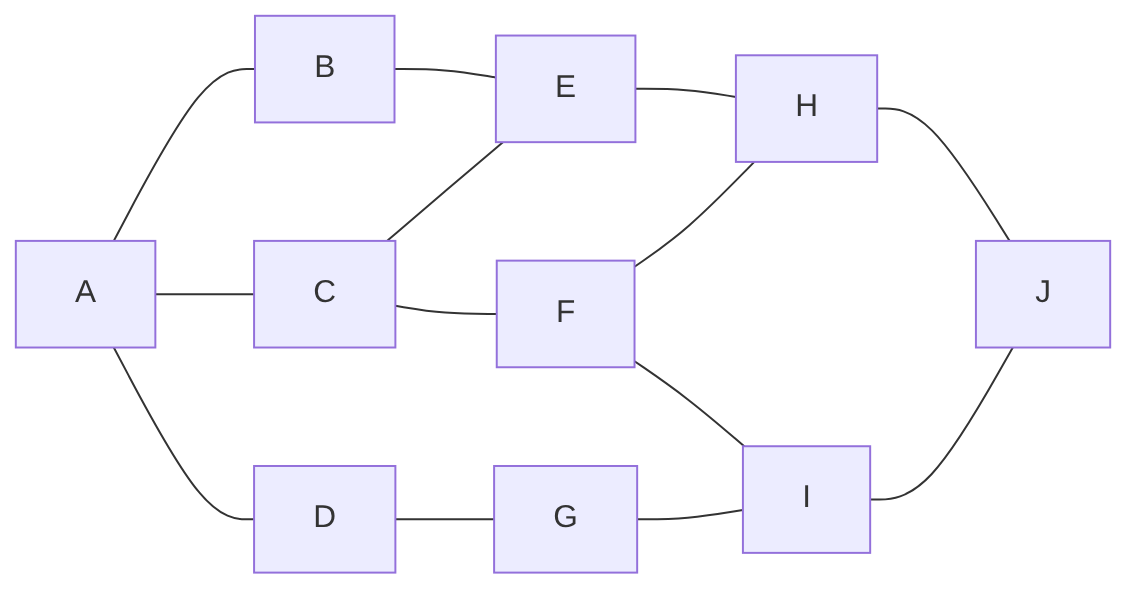

*Regra adotada para evitar duplicatas (Tarefa 4)*
- No grafo não direcionado, a aresta `{A, B}` está guardada **duas vezes** na lista (`B ∈ adj[A]` e `A ∈ adj[B]`). Exportar uma linha por entrada geraria 26 linhas para 13 arestas, como a célula mostra.
- **Regra:** cada aresta é identificada pela **tupla ordenada** `(min(u, v), max(u, v))`, que é a mesma vista de qualquer uma das pontas. Ao percorrer a lista, a primeira vez que o par aparece ele é exportado e registrado em um `set` de pares já exportados; na segunda vez (vindo da outra ponta), é ignorado. Custo $O(V + E)$, com consulta $O(1)$ ao `set`.
- **Validação por inspeção (Tarefa 3):** a célula lê de volta a própria string gerada com expressões regulares e confere que (a) o conjunto de arestas exportadas é igual ao de `ARESTAS` (13 de 13) e (b) não há linhas repetidas (13 linhas para 13 arestas). A imagem confirma visualmente.
- **Decisões complementares:**
  - `directed=True` exporta cada arco como `u --> v`, já que `u → v` e `v → u` são arcos diferentes;
  - `directed=False` exige que a lista seja simétrica; um arco sem o sentido inverso levanta `ValueError`, porque exportá-lo como não direcionado esconderia um erro de modelagem;
  - os vértices recebem identificadores `n0, n1, ...` com o nome como rótulo (nomes com hífen, espaço ou acento não quebram a sintaxe), e tudo sai em ordem alfabética, então a mesma entrada gera sempre a mesma string.

---
### Exercício 11: Integração: trie como índice de vértices (busca de vértice por prefixo)

**Introdução**
Integrações entre estruturas são comuns em sistemas reais: um grafo representa relações, enquanto uma trie pode servir como índice textual para localizar entidades (vértices) por prefixo. Em OO, o ganho é clareza: a Trie encapsula operações de busca textual, e o Grafo encapsula operações estruturais. A integração deve ser feita por uma função que coordene ambos: obter candidatos no índice (Trie) e confirmar existência no grafo. Esse exercício exige consistência entre as estruturas e evidência de que o índice não está desconectado do grafo.

**Tarefa**
1. Crie um conjunto de vértices com nomes textuais (ex.: produtos, usuários, serviços).
2. Insira todos esses nomes na trie.
3. Construa um grafo com esses vértices (lista de adjacência).
4. Implemente uma função `find_vertices_by_prefix(prefix, k)` que:
   - a. Usa autocomplete para obter candidatos.
   - b. Filtra apenas os candidatos que são vértices existentes no grafo.
5. Demonstre 3 consultas por prefixo e mostre os resultados.

In [11]:
# 1) Vértices com nomes textuais: serviços de uma plataforma de e-commerce
SERVICOS = ["api-gateway", "auth", "auth-admin", "carrinho", "catalogo", "catalogo-busca", "checkout",
            "cupons", "estoque", "estoque-reservas", "frete", "notificacoes", "notificacoes-email",
            "notificacoes-sms", "pagamentos", "pagamentos-pix", "pagamentos-cartao", "pedidos",
            "recomendacoes", "usuarios"]
DEPENDENCIAS = [("api-gateway", "auth"), ("api-gateway", "catalogo"), ("api-gateway", "carrinho"),
                ("api-gateway", "usuarios"), ("auth", "usuarios"), ("auth-admin", "auth"),
                ("carrinho", "catalogo"), ("carrinho", "cupons"), ("checkout", "carrinho"),
                ("checkout", "pagamentos"), ("checkout", "frete"), ("checkout", "pedidos"),
                ("catalogo", "estoque"), ("catalogo-busca", "catalogo"), ("pedidos", "estoque-reservas"),
                ("estoque-reservas", "estoque"), ("pedidos", "notificacoes"), ("notificacoes", "notificacoes-email"),
                ("notificacoes", "notificacoes-sms"), ("pagamentos", "pagamentos-pix"),
                ("pagamentos", "pagamentos-cartao"), ("recomendacoes", "catalogo"), ("recomendacoes", "usuarios")]

# 2) Índice textual: todos os nomes na Trie
indice = Trie()
for nome in SERVICOS:
    indice.insert(nome)

# 3) Grafo com os mesmos vértices (lista de adjacência)
servicos = GraphAdjList()
for nome in SERVICOS:
    servicos.add_vertex(nome)
for u, v in DEPENDENCIAS:
    servicos.add_edge(u, v)
print(f"Índice: {indice} | Grafo: {servicos}")


# 4) A função que coordena as duas estruturas
def find_vertices_by_prefix(trie, graph, prefix, k):
    """Até k vértices do grafo cujo nome começa com `prefix`, em ordem lexicográfica.
      a) obtém candidatos com trie.autocomplete;
      b) mantém só os candidatos que ainda são vértices do grafo.
    Se o filtro descartar candidatos (índice desatualizado), pede mais à Trie, dobrando
    a janela, até completar k ou esgotar o prefixo. Devolve (vértices, candidatos descartados)."""
    if k == 0:
        return [], []
    janela = k
    while True:
        candidatos = trie.autocomplete(prefix, janela)
        validos = [c for c in candidatos if c in graph.adj]
        descartados = [c for c in candidatos if c not in graph.adj]
        if len(validos) >= k or len(candidatos) < janela:     # completou k ou a Trie não tem mais nada
            return validos[:k], descartados
        janela *= 2


# 5) Três consultas por prefixo
for prefix, k in [("pag", 5), ("not", 2), ("ca", 3)]:
    vs, desc = find_vertices_by_prefix(indice, servicos, prefix, k)
    print(f"\nfind_vertices_by_prefix({prefix!r}, k={k}) -> {vs}")
    for v in vs:
        print(f"    {v:<20} dependências/vizinhos: {sorted(servicos.adj[v])}")
    assert vs == sorted(s for s in SERVICOS if s.startswith(prefix))[:k]

# Evidência de que o índice não está desconectado do grafo
print("\nConsistência índice x grafo:")
palavras_indice = set(indice._collect_words(indice.root, ""))
print(f"  toda palavra da Trie é vértice do grafo: {palavras_indice <= set(servicos.adj)}")
print(f"  todo vértice do grafo está na Trie: {set(servicos.adj) <= palavras_indice}")

# O filtro (b) em ação: um serviço é desligado no grafo, mas continua no índice
servicos.remove_vertex("pagamentos-cartao")
vs, desc = find_vertices_by_prefix(indice, servicos, "pag", 5)
print(f"\nApós remover 'pagamentos-cartao' só do grafo:")
print(f"  autocomplete('pag', 5) da Trie: {indice.autocomplete('pag', 5)}")
print(f"  find_vertices_by_prefix('pag', 5): {vs} | descartados pelo filtro: {desc}")
print(f"  toda palavra da Trie é vértice do grafo: {palavras_indice <= set(servicos.adj)}  <- o filtro impede que o resultado aponte para um vértice inexistente")
assert "pagamentos-cartao" not in vs and desc == ["pagamentos-cartao"]

# Janela crescente: com k=1 e o primeiro candidato inválido, a função pede mais candidatos à Trie
servicos.remove_vertex("notificacoes")
vs, desc = find_vertices_by_prefix(indice, servicos, "not", 1)
print(f"  com 'notificacoes' também removido: find_vertices_by_prefix('not', 1) -> {vs} (descartou {desc})")
assert vs == ["notificacoes-email"]

Índice: Trie(20 palavras, 142 nós) | Grafo: GraphAdjList(20 vértices, 23 arestas)

find_vertices_by_prefix('pag', k=5) -> ['pagamentos', 'pagamentos-cartao', 'pagamentos-pix']
    pagamentos           dependências/vizinhos: ['checkout', 'pagamentos-cartao', 'pagamentos-pix']
    pagamentos-cartao    dependências/vizinhos: ['pagamentos']
    pagamentos-pix       dependências/vizinhos: ['pagamentos']

find_vertices_by_prefix('not', k=2) -> ['notificacoes', 'notificacoes-email']
    notificacoes         dependências/vizinhos: ['notificacoes-email', 'notificacoes-sms', 'pedidos']
    notificacoes-email   dependências/vizinhos: ['notificacoes']

find_vertices_by_prefix('ca', k=3) -> ['carrinho', 'catalogo', 'catalogo-busca']
    carrinho             dependências/vizinhos: ['api-gateway', 'catalogo', 'checkout', 'cupons']
    catalogo             dependências/vizinhos: ['api-gateway', 'carrinho', 'catalogo-busca', 'estoque', 'recomendacoes']
    catalogo-busca       dependências/vizinhos: ['

*Análise*
- **Cenário (Tarefas 1 a 3):** 20 microsserviços de um e-commerce como vértices e 23 dependências como arestas. Os mesmos 20 nomes estão na Trie (142 nós).
- **Função (Tarefa 4):** recebe a Trie e o grafo como parâmetros, além de `prefix` e `k`, porque é ela que coordena as duas estruturas sem que uma conheça a outra. (a) pede candidatos ao `autocomplete`; (b) mantém só os que são chaves de `graph.adj`. Se o filtro descartar candidatos, ela pede mais à Trie, **dobrando a janela**, até completar `k` ou esgotar o prefixo; assim um índice desatualizado não faz a função devolver menos resultados do que existem.
- **Consultas (Tarefa 5):** `pag` (k=5) → os 3 serviços de pagamento; `not` (k=2) → os 2 primeiros de notificações; `ca` (k=3) → `carrinho`, `catalogo`, `catalogo-busca`. Cada uma mostra também os vizinhos do vértice no grafo, e é conferida por `assert`.
- **Evidência de que o índice não está desconectado do grafo:**
  - no estado inicial, toda palavra da Trie é vértice e todo vértice está na Trie;
  - depois de remover `pagamentos-cartao` **só do grafo**, o `autocomplete` ainda o devolve, mas `find_vertices_by_prefix` o descarta: o resultado nunca aponta para um vértice inexistente;
  - removendo também `notificacoes`, a consulta `not` com `k=1` descarta o primeiro candidato e busca o próximo (`notificacoes-email`), o que mostra a janela crescente funcionando.
- **Custo:** $O(p + \min(S, k' L) + k')$, com $k'$ = tamanho final da janela; cada filtro é uma consulta $O(1)$ ao dicionário `adj`.

---
### Exercício 12: Análise e justificativa técnica (alto rigor)

**Introdução**
Neste TP2, você não está apenas implementando estruturas, mas demonstrando maturidade em engenharia: justificar escolhas, avaliar trade-offs e produzir documentação técnica auditável. A OO aqui não é "estilo": ela é parte da estratégia de organização e manutenção do código. Este exercício consolida a entrega exigindo análise comparativa entre representações e operações, com custos em Big O, limites práticos e justificativas claras de decisões de projeto.

**Tarefa**
1. Produza uma seção no notebook intitulada **"Decisões de Projeto e Complexidade"** contendo:
   - a. Uma tabela com as operações principais da trie (`insert`, `search`, `starts_with`, `autocomplete`) e seus custos em Big O.
   - b. Uma tabela comparando **lista** vs **matriz** de adjacência para:
     - Inserção de aresta
     - Consulta de adjacência
     - Consumo de memória (descrito qualitativamente)
2. Justifique qual representação de grafo você escolheria para:
   - a. Um grafo esparso com milhões de vértices.
   - b. Um grafo denso com poucos vértices.
3. Inclua pelo menos 2 decisões técnicas justificadas com alto rigor:
   - a. Uma decisão na implementação da trie (estrutura de children, critério de desempate do autocorrect, etc.).
   - b. Uma decisão na implementação do grafo (lista vs conjunto, directed flag, regra de export Mermaid).

## Decisões de Projeto e Complexidade

**Variáveis:** $L$ = tamanho da palavra; $p$ = tamanho do prefixo; $S$ = nós da subárvore do prefixo; $k$ = sugestões pedidas; $L_{max}$ = maior palavra; $V$ = vértices; $E$ = arestas; $\text{grau}(v)$ = vizinhos de $v$.

**a) Operações da Trie**

| Operação | Custo (pior caso) | Por quê |
|---|---|---|
| `insert(word)` | $O(L)$ | um nó por caractere; cada passo é um acesso $O(1)$ médio a `children` (dict) |
| `search(word)` | $O(L)$ | desce o caminho e confere `is_end` no último nó |
| `starts_with(prefix)` | $O(p)$ | desce o caminho; não precisa de `is_end` |
| `autocomplete(prefix, k)` | $O(p + \min(S, k \cdot L_{max}))$ (alfabeto fixo) | desce até o prefixo e percorre em ordem lexicográfica até a $k$-ésima palavra |
| `_collect_words(node, prefix)` | $O(S + W \cdot L)$ | percorre a subárvore inteira e monta as $W$ palavras |
| `autocorrect(word)` | $O(L + L')$ | `search` + maior prefixo + primeira palavra da subárvore |

Nenhum custo depende do número total de palavras $n$. A célula abaixo confirma: com 1.000, 10.000 e 100.000 palavras, `search` deu exatamente 10,0 passos por consulta (palavras de 10 letras) e `starts_with` de 5 letras, 5,0 passos; com palavras de 5, 10, 20 e 40 letras, os passos foram 5, 10, 20 e 40. O tempo de relógio cresceu um pouco com $n$ por efeito de cache (mais nós espalhados na memória), não por mais trabalho.

**b) Lista vs matriz de adjacência**

| Critério | Lista de adjacência (`dict` de `set`) | Matriz de adjacência |
|---|---|---|
| Inserção de aresta | $O(1)$ médio | $O(1)$ |
| Inserção de vértice | $O(1)$ | $O(V)$: nova coluna em cada linha (medido: de alguns µs com 250 vértices para mais de 150 µs com 2.000; a lista ficou abaixo de 1 µs em todos) |
| Consulta de adjacência `has_edge(u, v)` | $O(1)$ médio com `set`; $O(\text{grau}(u))$ se fosse `list` | $O(1)$ garantido (acesso direto à célula) |
| Listar vizinhos | $O(\text{grau}(v))$ | $O(V)$ |
| Consumo de memória | proporcional ao que existe: $O(V + E)$; ótimo em grafos esparsos, mas cada `set` tem custo fixo por vértice | uma célula por par: $O(V^2)$, independente de quantas arestas existam; ótimo só quando a maioria dos pares está ligada |

**2) Qual representação usar**
- **a) Esparso com milhões de vértices: lista de adjacência.** Com $V = 10^6$, a matriz teria $10^{12}$ células; mesmo com 1 bit por célula seriam cerca de 125 GB, contra algumas centenas de MB para a lista em Python se cada vértice tiver poucos vizinhos. Além disso, adicionar um vértice custaria $O(V)$ e listar vizinhos, a operação central de BFS e DFS, custaria $O(V)$ por vértice, tornando uma travessia $O(V^2)$ em vez de $O(V + E)$. A medição do Exercício 8 já mostra a tendência em pequena escala: com 2.000 vértices e grau médio 4, a matriz usou cerca de 28× mais memória (34,28 MB contra cerca de 1,2 MB).
- **b) Denso com poucos vértices: matriz de adjacência.** Quando $E \approx V^2$, a lista não economiza memória e ainda paga o custo fixo de um `set` por vértice; no Exercício 8, com 300 vértices e metade dos pares ligados, a matriz usou 0,90 MB contra 2,82 MB da lista. A matriz dá `has_edge` em $O(1)$ garantido, é contígua por linha e permite operações de matriz (por exemplo, potências de $M$ contam caminhos). Com poucos vértices, o $O(V)$ de `add_vertex` não pesa.

**3) Decisões técnicas justificadas**

**a) Trie: `children` como `dict` + desempate lexicográfico no autocorrect**
- *`children` como `dict`:* a alternativa clássica é um array de tamanho fixo $\sigma$ por nó (por exemplo, 26 posições). O array dá acesso $O(1)$ garantido, mas gasta $\sigma$ posições em **todo** nó, inclusive nas folhas, que são a maioria; com acentos, hífens e maiúsculas, $\sigma$ passaria de 26 para centenas. O `dict` guarda só os filhos existentes (memória $O(\text{filhos})$) e aceita qualquer caractere Unicode, ao custo de $O(1)$ médio em vez de garantido. Como as palavras do Exercício 11 têm hífen e o vocabulário tem `ã` e `ç`, o `dict` é a escolha correta. O custo de ordenar as chaves a cada nó no percurso ($O(\sigma \log \sigma)$, com $\sigma$ pequeno na prática) é o preço de não manter os filhos ordenados.
- *Desempate do autocorrect:* "menor palavra em ordem lexicográfica entre as de maior prefixo comum" é (1) **total** (dois candidatos distintos nunca empatam no critério), (2) **independente da ordem de inserção** (verificado inserindo o vocabulário ao contrário), e (3) **barato**, porque coincide com a primeira palavra do percurso já usado pelo autocomplete: $O(L')$, sem coletar e comparar todas as candidatas. Critérios como "palavra mais curta" ou "mais frequente" exigiriam percorrer a subárvore inteira ou guardar contadores nos nós. A limitação aceita é que um erro nas primeiras letras leva a sugestões ruins (`cmputador` → `carro`); resolver isso exigiria distância de edição, fora do escopo deste exercício.

**b) Grafo: vizinhos em `set` + flag `directed` por aresta + regra de exportação**
- *`set` em vez de `list`:* garante, por construção, a **ausência de arestas duplicadas** (inserir `A–B` duas vezes não muda nada, verificado no Exercício 7) e dá `has_edge` em $O(1)$ médio, contra $O(\text{grau})$ de uma `list`. O custo é a ordem não determinística dos elementos, resolvida ordenando os vizinhos na impressão e na exportação, e um consumo de memória maior por vértice.
- *`directed` como parâmetro de `add_edge`:* permite modelar grafos mistos (o grafo de serviços poderia ter dependências de mão única). Como consequência, a exportação não direcionada precisa **verificar a simetria** antes de exportar, e `to_mermaid(directed=False)` levanta `ValueError` se encontrar um arco sem o inverso, em vez de produzir um diagrama enganoso.
- *Regra de exportação Mermaid:* a chave canônica `(min(u, v), max(u, v))` em um `set` de pares exportados garante cada aresta exatamente uma vez em $O(V + E)$; a ordenação alfabética e os identificadores `n0, n1, ...` tornam a saída determinística e segura para nomes com caracteres especiais. A verificação automática do Exercício 10 lê a string de volta e confere 13 arestas, sem repetição.

*Medições que sustentam as tabelas acima.* A última parte da saída lista a interface pública final de cada classe, ou seja, a arquitetura em OO: o estado em atributos e o comportamento em métodos.

In [12]:
import time, inspect

def tempo_medio(fn, args, reps=3):
    """Melhor de `reps` medições do tempo médio por chamada, em nanossegundos."""
    melhor = float("inf")
    for _ in range(reps):
        t0 = time.perf_counter()
        for a in args:
            fn(a)
        melhor = min(melhor, (time.perf_counter() - t0) / len(args) * 1e9)
    return melhor

# --- Trie: o custo depende do tamanho da palavra (L), não da quantidade de palavras (n) ---
rnd = random.Random(12)
letras = "abcdefghijklmnopqrst"
def palavra(L):
    return "".join(rnd.choice(letras) for _ in range(L))

def passos_medios(tr, metodo, args):
    total = 0
    for a in args:
        metodo(a); total += tr.last_steps
    return total / len(args)

print("Trie — palavras de tamanho L = 10, buscas de palavras existentes:")
print(f"{'n palavras':>12}{'nós':>11}{'passos/search':>15}{'passos/starts_with(5)':>23}"
      f"{'nós visitados autocomplete(2 letras, k=10)':>45}{'tempo search':>14}")
for n in [1_000, 10_000, 100_000]:
    tr = Trie()
    ws = [palavra(10) for _ in range(n)]
    for w in ws:
        tr.insert(w)
    alvos = [rnd.choice(ws) for _ in range(2000)]
    ps = passos_medios(tr, tr.search, alvos)
    pp = passos_medios(tr, tr.starts_with, [w[:5] for w in alvos])
    vis = 0
    for w in alvos[:500]:
        tr.autocomplete(w[:2], 10); vis += tr.last_visited
    ts = tempo_medio(tr.search, alvos)
    print(f"{n:>12,}{tr.nodes:>11,}{ps:>15.1f}{pp:>23.1f}{vis / 500:>45.1f}{ts:>12.0f}ns".replace(',', '.'))

print("\nTrie com 100.000 palavras — search em função do tamanho L da palavra buscada:")
tr = Trie()
base = [palavra(40) for _ in range(100_000)]
for w in base:
    tr.insert(w)
print(f"{'L':>6}{'passos/search':>15}")
for L in [5, 10, 20, 40]:
    print(f"{L:>6}{passos_medios(tr, tr.search, [w[:L] for w in rnd.sample(base, 2000)]):>15.1f}")

# --- Grafo: add_vertex é O(1) na lista e O(V) na matriz ---
print("\nGrafo — custo de add_vertex (µs) quando o grafo já tem V vértices:")
print(f"{'V':>7}{'lista':>10}{'matriz':>10}{'células da matriz':>20}")
for V in [250, 500, 1_000, 2_000]:
    gl, gx = GraphAdjList(), GraphAdjMatrix()
    for i in range(V):
        gl.add_vertex(i); gx.add_vertex(i)
    novos = list(range(V, V + 50))
    tl = tempo_medio(gl.add_vertex, novos, reps=1) / 1000
    tm = tempo_medio(gx.add_vertex, novos, reps=1) / 1000
    print(f"{V:>7,}{tl:>10.2f}{tm:>10.2f}{(V + 50) ** 2:>20,}".replace(',', '.'))

# --- Interface pública final das classes (arquitetura em OO) ---
print("\nInterface pública das classes:")
for cls in (TrieNode, Trie, GraphAdjList, GraphAdjMatrix):
    metodos = [m for m, f in vars(cls).items() if callable(f) and (not m.startswith('__') or m == '__init__')]
    print(f"  {cls.__name__}: {', '.join(metodos)}")

Trie — palavras de tamanho L = 10, buscas de palavras existentes:
  n palavras        nós  passos/search  passos/starts_with(5)   nós visitados autocomplete(2 letras, k=10)  tempo search
       1.000      8.330           10.0                    5.0                                         29.9         500ns
      10.000     75.775           10.0                    5.0                                         76.7         683ns


     100.000    681.269           10.0                    5.0                                         69.7        1012ns

Trie com 100.000 palavras — search em função do tamanho L da palavra buscada:


     L  passos/search
     5            5.0
    10           10.0
    20           20.0
    40           40.0

Grafo — custo de add_vertex (µs) quando o grafo já tem V vértices:
      V     lista    matriz   células da matriz
    250      0.13      5.20              90.000
    500      0.15      9.52             302.500
  1.000      0.13     62.93           1.102.500
  2.000      0.22    132.18           4.202.500

Interface pública das classes:
  TrieNode: __init__
  Trie: __init__, _validate, insert, _find_node, search, starts_with, _collect_words, words_with_prefix, _iter_words, autocomplete, _longest_prefix_node, autocorrect
  GraphAdjList: __init__, add_vertex, add_edge, has_edge, remove_vertex, vertices, degree, num_edges, print_adjacency, to_mermaid
  GraphAdjMatrix: __init__, add_vertex, add_edge, has_edge, neighbors, check_invariants, print_matrix
